# LAB 04 - Phân loại văn bản

Notebook này được tổ chức theo cấu trúc tham khảo của repository: kiểm tra dữ liệu, chia train/validation/test, mô hình cơ sở, so sánh biểu diễn, đánh giá trên test, phân tích lỗi và diễn giải mô hình. Dataset sử dụng là IMDb trong `aclImdb_v1.tar.gz`.

Chạy các cell theo thứ tự. Vectorizer và Word2Vec chỉ được fit trên tập train để tránh data leakage.

## 1. Import và cấu hình

In [1]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec
from preprocessing import load_imdb, average_vectors, train_word2vec, ROOT, SEED

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
MAX_ITERATIONS = 1000
BINARY_THRESHOLDS = (0.5, 0.8)
TOP_FEATURE_COUNT = 10
DATA_PATH = ROOT / 'aclImdb_v1.tar.gz'

## 2. Kiểm tra dataset

Kiểm tra số mẫu, missing values, văn bản trùng lặp, số lớp, phân bố lớp và độ dài văn bản trước khi train.

,Số dòng sau khi loại trùng,Missing text,Missing labels,Số classes,Số văn bản trùng còn lại
0,49577,0,0,2,0


,Lớp,Số lượng,Tỷ lệ (%)
0,0,24696,49.813422
1,1,24881,50.186578


mean       231.296529
median     173.000000
min          4.000000
max       2473.000000
Name: text, dtype: float64

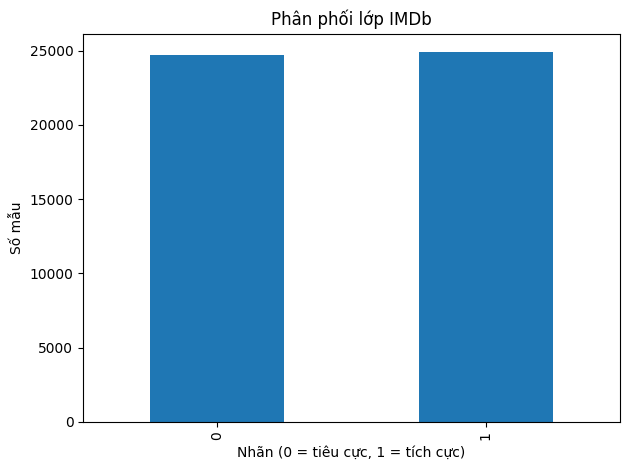

In [2]:
raw_data = load_imdb(DATA_PATH)
quality = pd.DataFrame([{
    'Số dòng sau khi loại trùng': len(raw_data),
    'Missing text': int(raw_data['text'].isna().sum()),
    'Missing labels': int(raw_data['label'].isna().sum()),
    'Số classes': int(raw_data['label'].nunique()),
    'Số văn bản trùng còn lại': int(raw_data['text'].duplicated().sum()),
}])
display(quality)
class_distribution = raw_data['label'].value_counts().sort_index().rename_axis('Lớp').reset_index(name='Số lượng')
class_distribution['Tỷ lệ (%)'] = 100 * class_distribution['Số lượng'] / len(raw_data)
display(class_distribution)
display(raw_data['text'].str.split().str.len().describe()[['mean', '50%', 'min', 'max']].rename({'50%':'median'}))
class_distribution.set_index('Lớp')['Số lượng'].plot(kind='bar', title='Phân phối lớp IMDb')
plt.xlabel('Nhãn (0 = tiêu cực, 1 = tích cực)'); plt.ylabel('Số mẫu'); plt.tight_layout()
plt.savefig(ROOT / 'class_distribution.png', dpi=160); plt.show()

## 3. Chia train/validation/test

Chia dữ liệu trước mọi bước `fit`: 60% train, 20% validation và 20% test. Validation dùng để chọn mô hình; test chỉ đánh giá một lần ở cuối.

In [3]:
train_pool, test_df = train_test_split(raw_data, test_size=TEST_SIZE, stratify=raw_data['label'], random_state=RANDOM_STATE)
train_df, validation_df = train_test_split(train_pool, test_size=VALIDATION_SIZE/(1-TEST_SIZE), stratify=train_pool['label'], random_state=RANDOM_STATE)
X_train, y_train = train_df.text.tolist(), train_df.label.to_numpy()
X_validation, y_validation = validation_df.text.tolist(), validation_df.label.to_numpy()
X_test, y_test = test_df.text.tolist(), test_df.label.to_numpy()
display(pd.DataFrame({'Tập': ['Train', 'Validation', 'Test'], 'Số mẫu': [len(X_train), len(X_validation), len(X_test)]}))

,Tập,Số mẫu
0,Train,29745
1,Validation,9916
2,Test,9916


## 4. Hàm đo lường

Dùng macro precision, recall và F1 để đánh giá cân bằng giữa hai lớp, thay vì chỉ nhìn accuracy.

In [4]:
def classification_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision_macro': precision, 'recall_macro': recall, 'f1_macro': f1}

def add_result(rows, name, representation, classifier, model, features, labels, seconds, vocab_size):
    rows.append({'model': name, 'representation': representation, 'classifier': classifier,
                 **classification_metrics(labels, model.predict(features)),
                 'training_time_seconds': seconds, 'vocabulary_size': vocab_size})

## 5. Baseline - TF-IDF + Logistic Regression

In [5]:
results_rows = []
tfidf_lr = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 1), min_df=2, max_df=0.95, sublinear_tf=True)),
                     ('classifier', LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE, solver='liblinear'))])
started = time.perf_counter(); tfidf_lr.fit(X_train, y_train); elapsed = time.perf_counter() - started
add_result(results_rows, 'TF-IDF + Logistic Regression', 'TF-IDF unigram', 'Logistic Regression', tfidf_lr, X_validation, y_validation, elapsed, len(tfidf_lr.named_steps['tfidf'].vocabulary_))
display(pd.DataFrame(results_rows))

,model,representation,classifier,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size
0,TF-IDF + Logistic Regression,TF-IDF unigram,Logistic Regression,0.897842,0.898112,0.897795,0.897816,4.234448,48415


## 6. Threshold cho phân loại nhị phân

In [6]:
classes = tfidf_lr.named_steps['classifier'].classes_; positive_index = list(classes).index(1)
probabilities = tfidf_lr.predict_proba(X_validation)[:, positive_index]
threshold_rows = []
for threshold in BINARY_THRESHOLDS:
    threshold_pred = np.where(probabilities >= threshold, 1, 0)
    p, r, f, _ = precision_recall_fscore_support(y_validation, threshold_pred, average='binary', zero_division=0)
    threshold_rows.append({'Threshold': threshold, 'Precision': p, 'Recall': r, 'F1': f})
display(pd.DataFrame(threshold_rows))

,Threshold,Precision,Recall,F1
0,0.5,0.888606,0.910571,0.899454
1,0.8,0.978567,0.587219,0.733986


## 7. So sánh Average Word2Vec + Logistic Regression

Word2Vec chỉ học trên `X_train`; validation và test chỉ được chuyển thành vector sau đó.

In [7]:
started = time.perf_counter()
w2v = train_word2vec(X_train)
X_train_w2v = average_vectors(w2v, X_train); X_validation_w2v = average_vectors(w2v, X_validation); X_test_w2v = average_vectors(w2v, X_test)
w2v_lr = LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE, solver='liblinear').fit(X_train_w2v, y_train)
w2v_elapsed = time.perf_counter() - started
add_result(results_rows, 'Average Word2Vec + Logistic Regression', 'Average Word2Vec', 'Logistic Regression', w2v_lr, X_validation_w2v, y_validation, w2v_elapsed, len(w2v.wv))
display(pd.DataFrame(results_rows).tail(1))

,model,representation,classifier,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size
1,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,0.862445,0.862536,0.862416,0.862428,154.166791,60570


## 8. Đặc trưng n-gram và Linear SVM

In [8]:
def train_tfidf_model(ngram_range, classifier):
    model = Pipeline([('tfidf', TfidfVectorizer(ngram_range=ngram_range, min_df=2, max_df=0.95, sublinear_tf=True)), ('classifier', classifier)])
    started = time.perf_counter(); model.fit(X_train, y_train); elapsed = time.perf_counter() - started
    return model, elapsed, len(model.named_steps['tfidf'].vocabulary_)

tfidf_bigram, bigram_elapsed, bigram_vocab = train_tfidf_model((1, 2), LogisticRegression(max_iter=MAX_ITERATIONS, random_state=RANDOM_STATE, solver='liblinear'))
add_result(results_rows, 'TF-IDF unigram + bigram + Logistic Regression', 'TF-IDF unigram + bigram', 'Logistic Regression', tfidf_bigram, X_validation, y_validation, bigram_elapsed, bigram_vocab)
tfidf_svm, svm_elapsed, svm_vocab = train_tfidf_model((1, 1), LinearSVC(random_state=RANDOM_STATE))
add_result(results_rows, 'TF-IDF + Linear SVM', 'TF-IDF unigram', 'Linear SVM', tfidf_svm, X_validation, y_validation, svm_elapsed, svm_vocab)
validation_table = pd.DataFrame(results_rows).sort_values('f1_macro', ascending=False)
display(validation_table)

,model,representation,classifier,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,vocabulary_size
2,TF-IDF unigram + bigram + Logistic Regression,TF-IDF unigram + bigram,Logistic Regression,0.901674,0.901923,0.901630,0.901651,14.491960,490246
0,TF-IDF + Logistic Regression,TF-IDF unigram,Logistic Regression,0.897842,0.898112,0.897795,0.897816,4.234448,48415
3,TF-IDF + Linear SVM,TF-IDF unigram,Linear SVM,0.894917,0.895005,0.894891,0.894906,3.981805,48415
1,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,0.862445,0.862536,0.862416,0.862428,154.166791,60570


## 9. Chọn mô hình bằng validation và đánh giá test

Chỉ chọn mô hình theo macro F1 trên validation; tập test được dùng một lần sau khi chọn xong.

In [9]:
model_map = {
    'TF-IDF + Logistic Regression': (tfidf_lr, X_test),
    'Average Word2Vec + Logistic Regression': (w2v_lr, X_test_w2v),
    'TF-IDF unigram + bigram + Logistic Regression': (tfidf_bigram, X_test),
    'TF-IDF + Linear SVM': (tfidf_svm, X_test),
}
best_name = validation_table.iloc[0]['model']; best_model, best_features = model_map[best_name]
best_test_pred = best_model.predict(best_features)
test_metrics = classification_metrics(y_test, best_test_pred)
test_result = {'model': best_name, 'split': 'test', **test_metrics, 'ghi_chu': 'Chọn theo macro F1 trên validation.'}
display(pd.DataFrame([test_result]))

,model,split,accuracy,precision_macro,recall_macro,f1_macro,ghi_chu
0,TF-IDF unigram + bigram + Logistic Regression,test,0.899355,0.899568,0.899311,0.899333,Chọn theo macro F1 trên validation.


## 10. Confusion matrix, error analysis và trọng số mô hình

,Dự đoán: tiêu cực,Dự đoán: tích cực
Thật: tiêu cực,4386,553
Thật: tích cực,445,4532


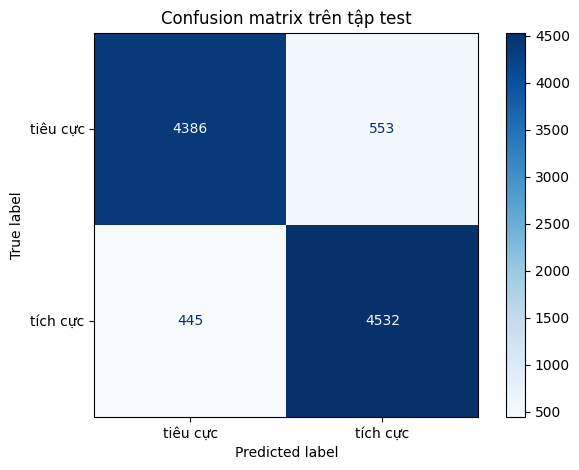

,Văn bản,Nhãn thật,Nhãn dự đoán
0,this movie was a sicky sweet cutesy romantic c...,1,1
2,the premise is amazing and the some of the act...,0,0
3,this is an absolute great show jessica alba be...,1,1


,Văn bản,Nhãn thật,Nhãn dự đoán
1,this wrestlemania just didn't do it for me whi...,1,0
29,last week i took a look at the weekly nielsen ...,0,1
33,an average tv movie quality totally formula st...,0,1


,Đặc trưng,Trọng số
18613,great,8.221254
14932,excellent,6.560671
4388,best,5.428730
31718,perfect,5.351350
47661,wonderful,5.082089
1748,amazing,4.749169
25632,loved,4.630770
47072,well,4.231761
17218,fun,4.214230
5743,brilliant,4.173752


,Đặc trưng,Trọng số
47786,worst,-9.793243
3398,bad,-8.614065
3255,awful,-6.660277
46844,waste,-6.605216
5327,boring,-6.348548
32748,poor,-5.762070
42913,terrible,-5.680009
29666,nothing,-5.153261
20577,horrible,-4.644842
47770,worse,-4.463418


In [10]:
matrix = confusion_matrix(y_test, best_test_pred, labels=[0, 1])
display(pd.DataFrame(matrix, index=['Thật: tiêu cực', 'Thật: tích cực'], columns=['Dự đoán: tiêu cực', 'Dự đoán: tích cực']))
ConfusionMatrixDisplay(matrix, display_labels=['tiêu cực', 'tích cực']).plot(cmap='Blues')
plt.title('Confusion matrix trên tập test'); plt.tight_layout(); plt.savefig(ROOT / 'confusion_matrix.png', dpi=160); plt.show()
examples = pd.DataFrame({'Văn bản': X_test, 'Nhãn thật': y_test, 'Nhãn dự đoán': best_test_pred})
display(examples[examples['Nhãn thật'] == examples['Nhãn dự đoán']].head(3))
display(examples[examples['Nhãn thật'] != examples['Nhãn dự đoán']].head(3))
lr_classifier = tfidf_lr.named_steps['classifier']; feature_names = tfidf_lr.named_steps['tfidf'].get_feature_names_out()
feature_weights = pd.DataFrame({'Đặc trưng': feature_names, 'Trọng số': lr_classifier.coef_[0]})
display(feature_weights.nlargest(TOP_FEATURE_COUNT, 'Trọng số')); display(feature_weights.nsmallest(TOP_FEATURE_COUNT, 'Trọng số'))

## 11. Word order và lưu kết quả

Average Word2Vec không giữ thứ tự từ; bigram có thể giữ lại các cụm như `not good`. Kết quả chi tiết cũng được lưu vào `results.csv`.

In [11]:
order_examples = ['not good', 'good not']
uni = TfidfVectorizer(ngram_range=(1, 1)).fit_transform(order_examples)
bi = TfidfVectorizer(ngram_range=(1, 2)).fit_transform(order_examples)
avg = average_vectors(w2v, order_examples)
order_table = pd.DataFrame([
    {'Biểu diễn': 'TF-IDF unigram', 'Độ tương đồng cosine': cosine_similarity(uni[0], uni[1])[0, 0]},
    {'Biểu diễn': 'TF-IDF unigram + bigram', 'Độ tương đồng cosine': cosine_similarity(bi[0], bi[1])[0, 0]},
    {'Biểu diễn': 'Average Word2Vec', 'Độ tương đồng cosine': cosine_similarity(avg[0].reshape(1, -1), avg[1].reshape(1, -1))[0, 0]},
])
display(order_table)
pd.DataFrame(results_rows).to_csv(ROOT / 'results_from_notebook.csv', index=False)
print('Đã lưu kết quả vào results_from_notebook.csv')

,Biểu diễn,Độ tương đồng cosine
0,TF-IDF unigram,1.000000
1,TF-IDF unigram + bigram,0.503103
2,Average Word2Vec,1.000000


Đã lưu kết quả vào results_from_notebook.csv
